# Canberra's children and a five-minute walk to a playground

How many Canberra children live within a five-minute walk of a public playground? This notebook takes the ACT
Government's 537 playgrounds, Canberra's 4,344 mesh blocks with residents (ABS 2021) and each mesh block's children
aged 0 to 14 (its residents times its SA1's share aged 0 to 14, from the 2021 Census), and the answer Plotlay worked
out on OpenStreetMap's paths and streets: how much of each mesh block's street length is within 400 m of a playground
walking along the paths (five minutes at 4.8 km/h), and how much is within 400 m in a straight line.

It reads only the files in `../data`. A mesh block's children count as within the walk in the share of its streets
that is: a block with 60% of its streets within 400 m counts 60% of its children.

**Read it carefully.** The children are an estimate (mesh blocks have no age counts; the SA1's share is spread evenly).
The paths are OpenStreetMap's as of 22 November 2026: a missing path makes a walk longer than it is, a mapped path
through a fence shorter. A playground counts from the nearest path to its point, not its gate.

In [1]:
import json
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, ListedColormap
DATA = '../data'
pd.set_option('display.width', 140)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})
N = json.load(open(f'{DATA}/numbers.json'))
mb = pd.read_csv(f'{DATA}/tables/meshblocks.csv', dtype={'mb': str})
pg = pd.read_csv(f'{DATA}/tables/playgrounds.csv')
print(len(mb), 'mesh blocks,', int(mb.residents.sum()), 'residents,', round(mb.children.sum()), 'children,', len(pg), 'playgrounds')

4344 mesh blocks, 448430 residents, 82789 children, 537 playgrounds


## The headline

Each mesh block's children times the share of its streets within the walk, summed, over all the children.

In [2]:
C = mb.children.sum()
rows = {'Walking 400 m along the paths (5 minutes)': mb.children_walk5.sum(), '400 m as the crow flies': mb.children_line5.sum(), 'Walking 800 m along the paths (10 minutes)': mb.children_walk10.sum()}
head = pd.DataFrame({'children': {k: round(v) for k, v in rows.items()}, 'share_pct': {k: round(100 * v / C, 1) for k, v in rows.items()}})
assert head.share_pct.iloc[0] == N['totals']['pct_walk5'] and head.share_pct.iloc[1] == N['totals']['pct_line5']
head

,children,share_pct
Walking 400 m along the paths (5 minutes),40907,49.4
400 m as the crow flies,67652,81.7
Walking 800 m along the paths (10 minutes),78178,94.4


## The straight line, checked afresh

The crow-flies share in the table came from Plotlay. Here it is again from the playgrounds' points alone: each mesh
block's point inside it, and whether it is within 400 m of any playground (in Australian Albers, EPSG:3577, so the
400 m is metres). A point is cruder than a block's streets, so the two agree only roughly.

In [3]:
pts = gpd.GeoDataFrame(mb, geometry=gpd.points_from_xy(mb.lng, mb.lat), crs=4326).to_crs(3577)
play = gpd.GeoDataFrame(pg, geometry=gpd.points_from_xy(pg.lng, pg.lat), crs=4326).to_crs(3577)
near = gpd.sjoin_nearest(pts, play[['asset_id', 'geometry']], distance_col='to_playground_m')
near = near[~near.index.duplicated()]
inside = near.to_playground_m <= 400
print(f"Mesh block points within 400 m of a playground: {100 * near.children[inside].sum() / C:.1f}% of the children")
print(f"From the streets (the table): {100 * mb.children_line5.sum() / C:.1f}%")
print(f"Median straight-line distance from a child's mesh block to a playground: {near.to_playground_m.repeat(near.children.round().astype(int).clip(lower=0)).median():.0f} m")

Mesh block points within 400 m of a playground: 82.7% of the children
From the streets (the table): 81.7%
Median straight-line distance from a child's mesh block to a playground: 258 m


## By district

,children,children_walk5,children_line5,children_walk10,pct_walk5,pct_line5,pct_walk10
district,,,,,,,
South Canberra,4324.0,1058.0,2279.0,3253.0,24.0,53.0,75.0
Woden Valley,6754.0,2817.0,5166.0,6164.0,42.0,76.0,91.0
North Canberra,7332.0,3111.0,5352.0,6523.0,42.0,73.0,89.0
Canberra East,109.0,49.0,56.0,56.0,45.0,52.0,51.0
Tuggeranong,17207.0,8446.0,13844.0,16218.0,49.0,80.0,94.0
Molonglo,2663.0,1368.0,2276.0,2573.0,51.0,86.0,97.0
Weston Creek,4812.0,2535.0,4402.0,4681.0,53.0,92.0,97.0
Belconnen,19272.0,10358.0,16898.0,18790.0,54.0,88.0,98.0
Gungahlin,20316.0,11164.0,17378.0,19919.0,55.0,86.0,98.0


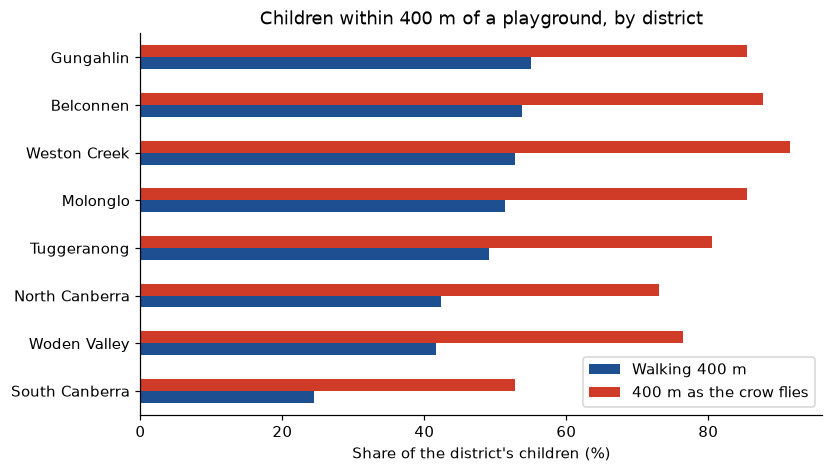

In [4]:
d = mb.groupby('district')[['children', 'children_walk5', 'children_line5', 'children_walk10']].sum()
for k in ('walk5', 'line5', 'walk10'): d[f'pct_{k}'] = (100 * d[f'children_{k}'] / d.children).round(1)
d = d.sort_values('pct_walk5')
ax = d[d.children >= 1000][['pct_walk5', 'pct_line5']].rename(columns={'pct_walk5': 'Walking 400 m', 'pct_line5': '400 m as the crow flies'}).plot.barh(figsize=(8, 4.5), color=['#1d4f91', '#cf3b26'])
ax.set_xlabel('Share of the district\'s children (%)'); ax.set_ylabel(''); ax.set_title('Children within 400 m of a playground, by district')
d.round(0)

## The suburbs that fall short

Suburbs with 300 children or more, lowest share within the walk first, with the straight-line share beside it.

In [5]:
s = pd.read_csv(f'{DATA}/tables/suburbs.csv')
s[s.compared == 'yes'].sort_values('pct_walk5')[['suburb', 'children', 'playgrounds', 'pct_walk5', 'pct_line5', 'pct_walk10']].head(15)

,suburb,children,playgrounds,pct_walk5,pct_line5,pct_walk10
67,Kingston,575,1,6.6,28.7,47.3
81,Yarralumla,480,2,11.4,27.9,53.7
91,Turner,341,2,17.1,48.0,86.2
93,Oxley,332,2,20.4,78.6,87.2
92,Braddon,334,1,23.1,38.5,69.8
47,Denman Prospect,701,4,23.8,55.1,87.2
31,Ainslie,890,5,26.1,72.0,91.3
51,Griffith,683,5,26.9,54.4,84.0
24,Banks,1092,3,28.9,65.8,89.3
72,Deakin,529,3,29.3,68.7,89.6


## The map

Each mesh block by the share of its streets within the walk.

Text(0.5, 1.0, 'Streets within a 5-minute walk of a playground (%), and the playgrounds')

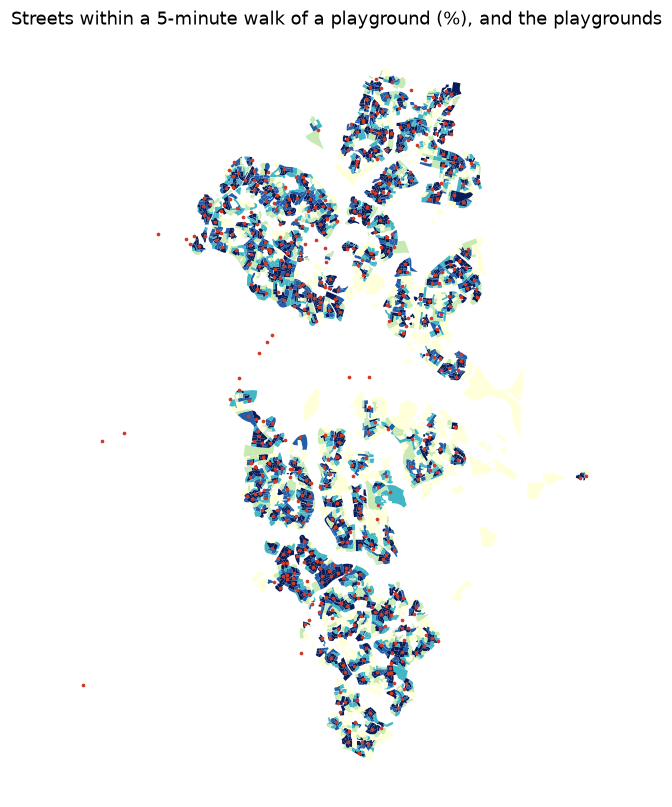

In [6]:
g = gpd.read_file(f'{DATA}/geometry/meshblocks.geojson')
cmap = ListedColormap(['#ffffd9', '#c7e9b4', '#41b6c4', '#225ea8', '#081d58']); norm = BoundaryNorm([0, 1, 25, 50, 75, 100.01], cmap.N)
ax = g.plot(column='pct_streets_walk5', cmap=cmap, norm=norm, figsize=(7, 9), linewidth=0, missing_kwds={'color': '#d4d4d8'})
gpd.read_file(f'{DATA}/geometry/playgrounds.geojson').plot(ax=ax, markersize=2, color='#cf3b26')
ax.set_axis_off(); ax.set_title('Streets within a 5-minute walk of a playground (%), and the playgrounds')